In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### 1. Find the problems

In [4]:
m = pd.read_csv('machines.csv')
p = pd.read_csv('production_log.csv')

In [17]:
m.shape

(6, 4)

In [16]:
p.shape

(2073, 6)

In [18]:
m.head(10)

,machine_id,type,plant,install_year
0,M01,CNC,North,2015
1,M02,CNC,North,2019
2,M03,Press,North,2012
3,M04,Press,South,2020
4,M05,Welder,South,2017
5,M06,Welder,South,2022


In [6]:
p.head()

,date,machine_id,shift,units,defects,downtime_min
0,2025-01-01,M01,Night,81.0,7,90
1,2025-01-01,M02,Day,132.0,7,67
2,2025-01-01,M03,Day,160.0,11,71
3,2025-01-01,M04,Day,199.0,8,50
4,2025-01-01,M06,Day,79.0,1,37


In [12]:
m.isna().sum()

machine_id      0
type            0
plant           0
install_year    0
dtype: int64

In [13]:
p.isna().sum()

date             0
machine_id       0
shift            0
units           20
defects          0
downtime_min     0
dtype: int64

In [14]:
m.duplicated().sum()

np.int64(0)

In [24]:
p.duplicated().sum()

np.int64(12)

In [20]:
p.describe()

,units,defects,downtime_min
count,2053.000000,2073.000000,2073.000000
mean,117.212859,6.608297,67.686445
std,45.566704,3.648923,21.653602
min,-1.000000,0.000000,0.000000
25%,78.000000,4.000000,52.000000
50%,105.000000,6.000000,66.000000
75%,161.000000,9.000000,83.000000
max,240.000000,18.000000,138.000000


In [21]:
m.dtypes

machine_id        str
type              str
plant             str
install_year    int64
dtype: object

In [22]:
p.dtypes

date                str
machine_id          str
shift               str
units           float64
defects           int64
downtime_min      int64
dtype: object

In [25]:
p['shift'].value_counts()

shift
Day      1012
Night    1001
NIGHT      20
day        15
DAY        15
night      10
Name: count, dtype: int64

In [26]:
p['machine_id'].value_counts()

machine_id
M01    346
M06    346
M05    345
M03    344
M04    342
M02    335
M07     15
Name: count, dtype: int64

In [27]:
m['machine_id'].value_counts()

machine_id
M01    1
M02    1
M03    1
M04    1
M05    1
M06    1
Name: count, dtype: int64

In [28]:
p['date'].str.contains('.', regex=False).sum()

np.int64(25)

In [29]:
(p['units'] < 0).sum()

np.int64(8)

In [31]:
p['shift'].isin(['Day', 'Night']).sum()

np.int64(2013)

In [32]:
p.shape[0] - 2013

60

### 2. Clean the log

In [38]:
def clean(p):
    p = p.copy()
    p['date'] = pd.to_datetime(p['date'], format='mixed', dayfirst=True)
    p['shift'] = p['shift'].str.strip().str.capitalize()
    p = p.drop_duplicates()
    p.loc[p['units'] < 0, 'units'] = np.nan
    p = p.dropna(subset=['units'])

    return p

In [58]:
c = clean(p)
print(c['date'].dtype, c['date'].isna().sum())
print(c['shift'].nunique())
print(c.duplicated().sum())
print((c['units'] < 0).sum())

datetime64[us] 0
2
0
0


“I dropped the rows with missing or negative units because the real count is unknown, filling them with a mean would invent production that never happened, and they are only about 1.4% of the rows.”

In [49]:
print(c['date'].min(), c['date'].max())

2025-01-01 00:00:00 2025-12-31 00:00:00


### 3. Merge with the machine table

In [50]:
print(m['machine_id'].tolist())
print(c['machine_id'].unique())

['M01', 'M02', 'M03', 'M04', 'M05', 'M06']
<ArrowStringArray>
['M01', 'M02', 'M03', 'M04', 'M06', 'M05', 'M07']
Length: 7, dtype: str


In [51]:
unknown = ~c['machine_id'].isin(m['machine_id'])
print(unknown.sum())
print(c[unknown]['machine_id'].unique())

15
<ArrowStringArray>
['M07']
Length: 1, dtype: str


“I drop the M07 rows because M07 is not in the machine table, so I cannot know its type, plant or age, and it would break the type, plant and age results.”

In [55]:
df = pd.merge(c, m, on='machine_id', how='inner')
df['machine_age'] = 2025 - df['install_year']

In [56]:
unknown_rows = c[~c['machine_id'].isin(m['machine_id'])]
print(len(unknown_rows))

15


In [57]:
print(df['type'].isna().sum(), df['plant'].isna().sum(), df['install_year'].isna().sum())
print(len(df), len(c) - 15)
print(df['machine_id'].unique())

0 0 0
2018 2018
<ArrowStringArray>
['M01', 'M02', 'M03', 'M04', 'M06', 'M05']
Length: 6, dtype: str


### 4. Monthly output


In [59]:
df['month'] = df['date'].dt.month
monthly = df.groupby('month')['units'].sum()

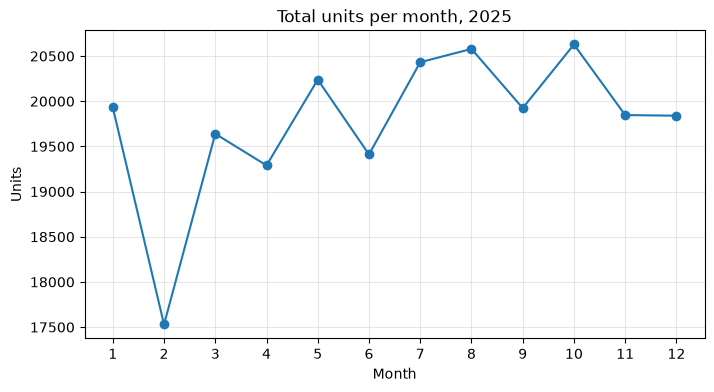

In [60]:
plt.figure(figsize=(8, 4))
plt.plot(monthly.index, monthly.values, marker='o')
plt.title('Total units per month, 2025')
plt.xlabel('Month')
plt.ylabel('Units')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.show()

In [61]:
daily_avg = df.groupby('month')['units'].mean()

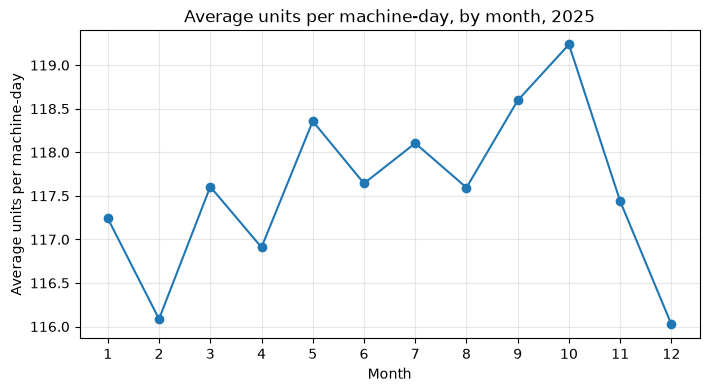

In [65]:
plt.figure(figsize=(8, 4))
plt.plot(daily_avg.index, daily_avg.values, marker='o')
plt.title('Average units per machine-day, by month, 2025')
plt.xlabel('Month')
plt.ylabel('Average units per machine-day')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.show()

“Output is roughly steady, at about 19,500 to 20,600 units a month from March to December. February is the lowest (about 17,500), mostly because it has only 28 days, and the peak is in October (about 20,600).”

### 5. Defect rate

In [66]:
df['defect_rate'] = df['defects']  / df['units']

In [67]:
df['defect_rate'].describe()

count    2018.000000
mean        0.054954
std         0.020447
min         0.000000
25%         0.041043
50%         0.054264
75%         0.069535
max         0.109589
Name: defect_rate, dtype: float64

In [68]:
by_type = df.groupby('type')['defect_rate'].mean()
by_shift = df.groupby('shift')['defect_rate'].mean()
print(by_type)
print(by_shift)

type
CNC       0.056860
Press     0.060335
Welder    0.047807
Name: defect_rate, dtype: float64
shift
Day      0.050123
Night    0.059842
Name: defect_rate, dtype: float64


In [69]:
g = df.groupby('type')[['defects', 'units']].sum()
g['rate'] = g['defects'] / g['units']
print(g)

        defects     units      rate
type                               
CNC        4010   70838.0  0.056608
Press      6942  116768.0  0.059451
Welder     2352   49684.0  0.047339


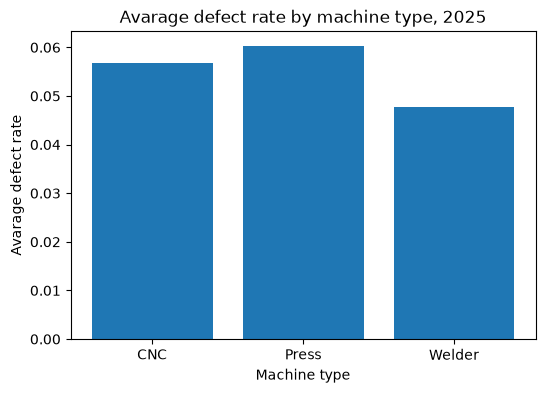

In [71]:
plt.figure(figsize=(6,4))
plt.bar(by_type.index, by_type.values)
plt.title('Avarage defect rate by machine type, 2025')
plt.xlabel('Machine type')
plt.ylabel('Avarage defect rate')
plt.show()

In [73]:
print(by_shift)

g = df.groupby('shift')[['defects', 'units']].sum()
g['rate'] = g['defects'] / g['units']
print(g)

shift
Day      0.050123
Night    0.059842
Name: defect_rate, dtype: float64
       defects     units      rate
shift                             
Day       6453  126215.0  0.051127
Night     6851  111075.0  0.061679


In [74]:
print(df.groupby(['type', 'shift'])['defect_rate'].mean())

type    shift
CNC     Day      0.052611
        Night    0.061452
Press   Day      0.054367
        Night    0.066691
Welder  Day      0.042921
        Night    0.052215
Name: defect_rate, dtype: float64


### 6. Machine age

In [75]:
result = df.groupby('machine_id').agg(
    downtime=('downtime_min', 'mean'),
    age=('machine_age', 'first')
)
print(result)

             downtime  age
machine_id                
M01         78.620588   10
M02         59.675758    6
M03         95.523810   13
M04         56.525680    5
M05         68.289086    8
M06         47.298246    3


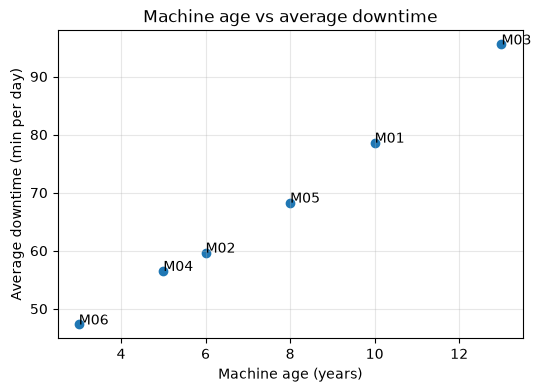

In [ ]:
plt.figure(figsize=(6, 4))
plt.scatter(result['age'], result['downtime'])
plt.title('Machine age vs average downtime')
plt.xlabel('Machine age (years)')
plt.ylabel('Average downtime (min per day)')
plt.grid(True, alpha=0.3)

for mid, row in result.iterrows():
    plt.annotate(mid, (row['age'], row['downtime']))
 
plt.show()

In [79]:
print(result['age'].corr(result['downtime']))

0.996928343091933


In [80]:
import numpy as np
slope, intercept = np.polyfit(result['age'], result['downtime'], 1)
print(slope)

4.769572896480679


### 7. Weekday pattern


In [82]:
df['weekday'] = df['date'].dt.day_name()
print(df[['date', 'weekday']].head())

        date    weekday
0 2025-01-01  Wednesday
1 2025-01-01  Wednesday
2 2025-01-01  Wednesday
3 2025-01-01  Wednesday
4 2025-01-01  Wednesday


In [85]:
by_weekday = df.groupby('weekday')['units'].mean()

In [86]:
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
by_weekday = by_weekday.reindex(order)
print(by_weekday)

weekday
Monday       116.799296
Tuesday      120.253521
Wednesday    117.551020
Thursday     117.802676
Friday       116.681818
Saturday     117.063158
Sunday       116.958042
Name: units, dtype: float64


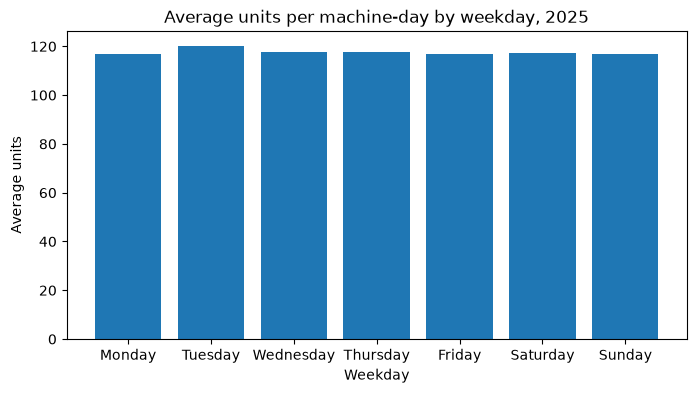

In [87]:
plt.figure(figsize=(8, 4))
plt.bar(by_weekday.index, by_weekday.values)
plt.title('Average units per machine-day by weekday, 2025')
plt.xlabel('Weekday')
plt.ylabel('Average units')
plt.show()

In [88]:
print(by_weekday.idxmax(), by_weekday.max())
print(by_weekday.idxmin(), by_weekday.min())
print(by_weekday.max() - by_weekday.min())

Tuesday 120.25352112676056
Friday 116.68181818181819
3.5717029449423734


“This answer will change my decision by telling the manager that no weekday needs special attention, so staffing and maintenance do not need a weekday-specific fix.”

### 8. Report function and dashboard